# Measurements

A QPSK link from bits to bits, measured with probes: spectrum, eye,
constellation, SNR, power and bit errors. The numbers are checked against
theory, and the same probes then drive a live dashboard.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

import sigline as sl

sps, Rs = 8, 1000.0  # samples per symbol, symbol rate / Hz
fs = sps * Rs
esn0_db = 10.0  # Es/N0 at the decision
n_sym = 200_000

## The link

Bits, Gray-mapped to QPSK (`Mapper(psk(4))`), shaped by a root-raised-cosine
`PulseShaper`; complex noise added; `MatchedFilter`; `Downsample` to one
sample per symbol; `Demapper` back to bits.

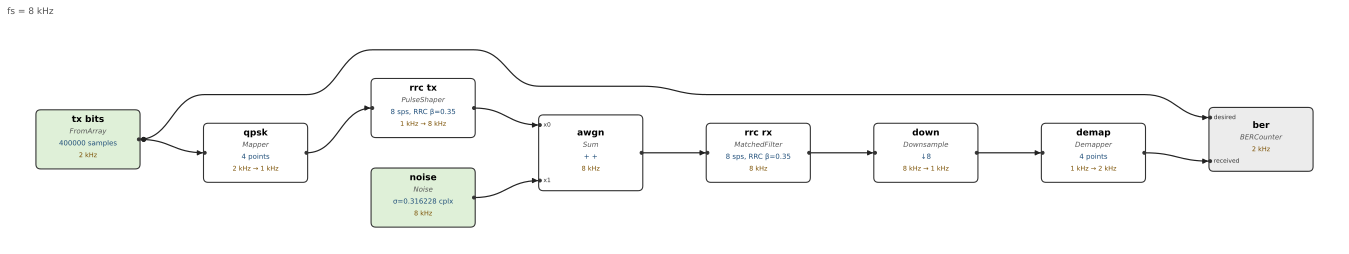

In [2]:
rng = np.random.default_rng(1)
bits = rng.integers(0, 2, 2 * n_sym)

tx_bits = sl.FromArray(bits.astype(float), fs=2 * Rs, name="tx bits")
qpsk = sl.Mapper(sl.psk(4), name="qpsk")
shape = sl.PulseShaper(sps, beta=0.35, span=10, name="rrc tx")
add = sl.Sum(name="awgn")
mf = sl.MatchedFilter(sps, beta=0.35, span=10, name="rrc rx")
down = sl.Downsample(sps, name="down")
demap = sl.Demapper(sl.psk(4), name="demap")
ber = sl.BERCounter(sync=500, name="ber")

tx_bits >> qpsk >> shape >> add["x0"]
sl.Noise(10 ** (-esn0_db / 20), seed=2, complex=True, name="noise") >> add["x1"]
add >> mf >> down >> demap >> ber["received"]
tx_bits >> ber["desired"]

d = sl.Diagram(ber, fs=fs)
d

## Probes

Measurements attach to any signal without changing the diagram.

In [3]:
QPSK = sl.psk(4)
spec = d.probe("rrc tx", sink=sl.SpectrumAnalyzer(nfft=1024, name="tx"))
eye = d.probe("rrc rx", sink=sl.EyeDiagram(sps, offset=0, name="matched filter"))
const = d.probe("down", sink=sl.ConstellationScope(QPSK, keep=2000, skip=20, name="rx"))
snr = d.probe("down", sink=sl.SNREstimator("dd", constellation=QPSK, skip=20))
power = d.probe("rrc tx", sink=sl.PowerMeter(interval=5.0))

d.run(n=n_sym * sps, chunk=4096)
print(ber.summary())

ber: BER 6.842e-04 (273/399000 bits), 95% CI [6.05e-04, 7.70e-04], delay 20 bits


## Against theory

With unit-energy pulses the decision sees $E_s/N_0$ directly. Gray QPSK has
$\mathrm{BER} = \tfrac12 \operatorname{erfc}\sqrt{E_b/N_0}$ with
$E_b = E_s/2$; MER and decision-directed SNR equal $E_s/N_0$; the transmit
power per sample is $1/\text{sps}$.

In [4]:
ebn0 = 10 ** (esn0_db / 10) / 2
lo, hi = ber.confidence()
theory = 0.5 * erfc(np.sqrt(ebn0))
print(f"BER    {ber.ber:.2e}  theory {theory:.2e}  95% CI [{lo:.2e}, {hi:.2e}]")
print(f"MER    {const.mer_db:.2f} dB  theory {esn0_db:.2f} dB")
print(f"SNR dd {snr.snr_db:.2f} dB")
print(f"power  {power.level:.2f} dB  theory {10 * np.log10(1 / sps):.2f} dB")

BER    6.84e-04  theory 7.83e-04  95% CI [6.05e-04, 7.70e-04]
MER    10.02 dB  theory 10.00 dB
SNR dd 10.02 dB
power  -9.03 dB  theory -9.03 dB


MER, SNR and power hit theory to 0.03 dB. The BER here is 273 errors where
312 are expected, 2.2 standard deviations low: a 95 % interval misses the
true value in one run of twenty. Over 3.2 million bits the same link gives
2492 errors against 2498 expected.

## A dashboard

Every measurement plots into any matplotlib axes, so they compose freely.

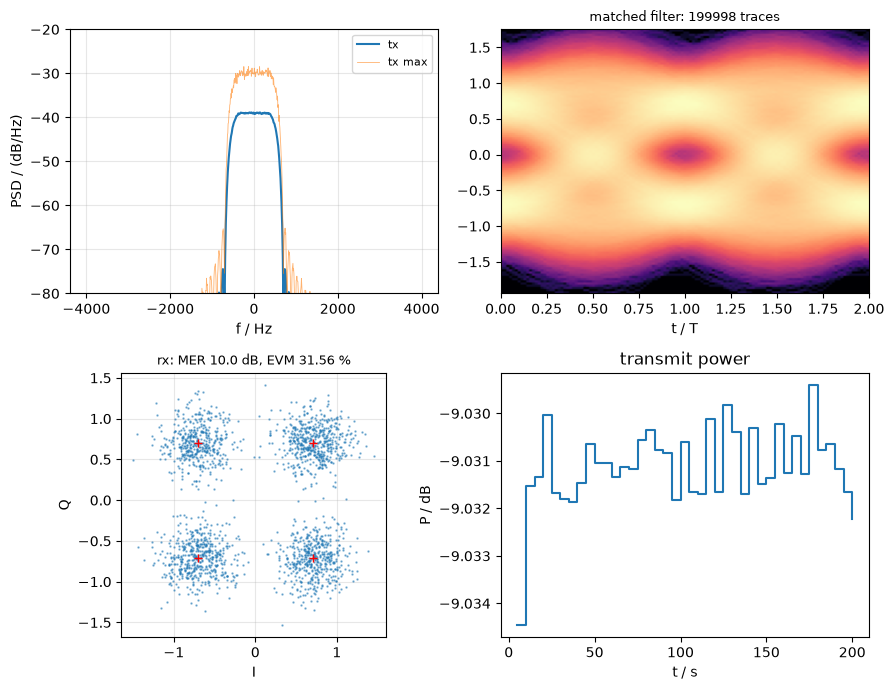

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(9, 7))
spec.plot(ax=ax[0, 0])
ax[0, 0].set_ylim(-80, -20)
eye.plot(ax=ax[0, 1])
const.plot(ax=ax[1, 0])
t = power.readings_t
ax[1, 1].step(t, power.readings, where="post")
ax[1, 1].set(xlabel="t / s", ylabel="P / dB", title="transmit power")
fig.tight_layout()
plt.show()

## Live

The same probes on a running diagram: a looping source, an exponentially
averaged spectrum, and `sl.watch` redrawing two panels.

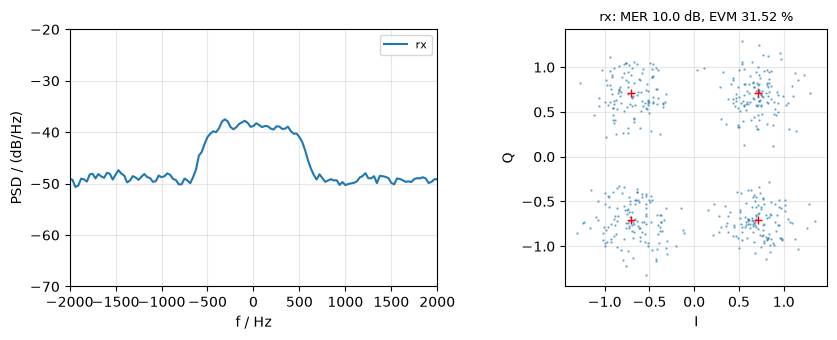

ber: BER 1.000e-03 (5/5000 bits), 95% CI [3.25e-04, 2.33e-03], delay 20 bits


In [6]:
tx_bits.loop = True
d.remove_probe(spec)
spec = d.probe(
    "awgn", sink=sl.SpectrumAnalyzer(nfft=256, average="exp", alpha=0.05, name="rx")
)
const.keep = 500


def draw(fig):
    a1, a2 = fig.subplots(1, 2)
    spec.plot(ax=a1, max_hold=False)
    a1.set_ylim(-70, -20)
    a1.set_xlim(-2000, 2000)
    const.plot(ax=a2)
    fig.tight_layout()


d.reset()
d.start(3.0, chunk=1024)
fig = sl.watch(d, draw, interval=0.3, figsize=(9, 3.5))
print(ber.summary())

## Summary

- `SpectrumAnalyzer`, `PowerMeter`, `ConstellationScope`, `EyeDiagram`,
  `SNREstimator`, `BERCounter`: blocks or probes (`d.probe(..., sink=...)`).
- MER, SNR and power match theory; BER within its statistics.
- Each `.plot(ax=...)` composes into any figure, also live with `sl.watch`.